In [19]:
import pandas as pd
import matplotlib.pyplot as plt

colors = {"Female": "#FF876F", "Male": "#4F0433"}

## Task 1
Read in the file on number of colon cancer cases (the file cases.tsv) and make sure that you understand the variables included. Create a graph showing the number of cases by age group and sex. Describe what you can conclude from the graph.

In [20]:
# investigate the data
cases = pd.read_csv("cases.tsv", sep="\t")
print(cases.head())

  agegroup  year   sex  n
0      0-4  2022  Male  0
1      5-9  2022  Male  0
2    10-14  2022  Male  1
3    15-19  2022  Male  8
4    20-24  2022  Male  5


In [21]:
print(cases.info())
print(cases.describe())

<class 'pandas.DataFrame'>
RangeIndex: 1908 entries, 0 to 1907
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   agegroup  1908 non-null   str  
 1   year      1908 non-null   int64
 2   sex       1908 non-null   str  
 3   n         1908 non-null   int64
dtypes: int64(2), str(2)
memory usage: 59.8 KB
None
              year            n
count  1908.000000  1908.000000
mean   1996.000000    96.734277
std      15.301069   122.679865
min    1970.000000     0.000000
25%    1983.000000     4.000000
50%    1996.000000    28.000000
75%    2009.000000   177.250000
max    2022.000000   621.000000


In [22]:
print(cases['agegroup'].value_counts())
print(cases['sex'].value_counts())

agegroup
0-4      106
5-9      106
10-14    106
15-19    106
20-24    106
25-29    106
30-34    106
35-39    106
40-44    106
45-49    106
50-54    106
55-59    106
60-64    106
65-69    106
70-74    106
75-79    106
80-84    106
85-89    106
Name: count, dtype: int64
sex
Male      954
Female    954
Name: count, dtype: int64


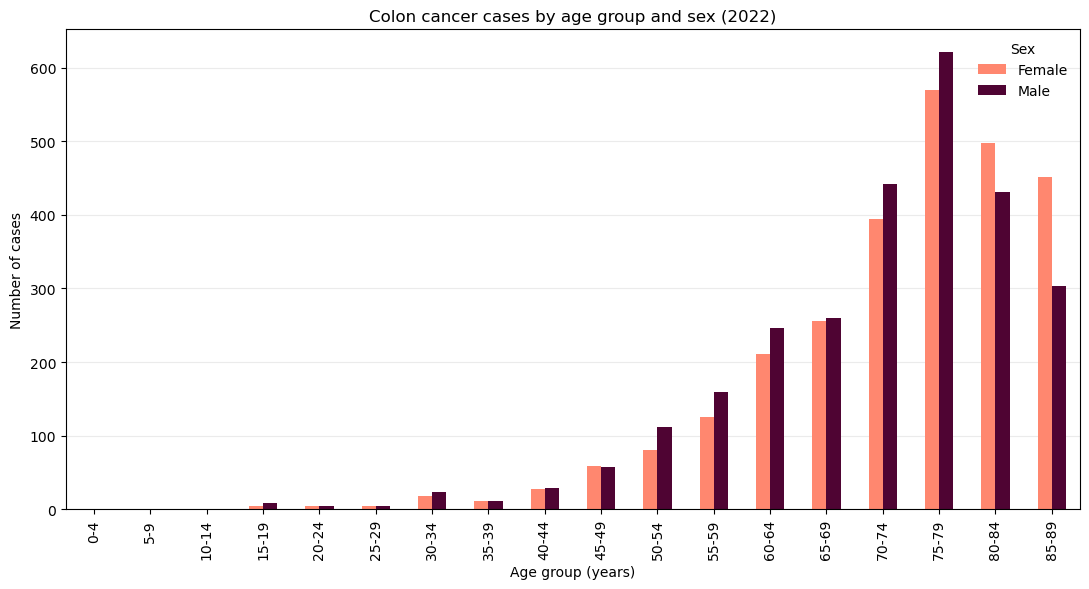

In [23]:
# create a graph of the number of cases by age group and sex for 2022
year_to_plot = cases["year"].max()
age_order = sorted(cases["agegroup"].unique(), key=lambda age: int(age.split("-")[0]))
case_counts = (
    cases.loc[cases["year"].eq(year_to_plot)]
    .pivot(index="agegroup", columns="sex", values="n")
    .reindex(age_order)
)

ax = case_counts.plot(
    kind="bar",
    figsize=(11, 6),
    color=[colors[sex] for sex in case_counts.columns],
)
ax.set_title(f"Colon cancer cases by age group and sex ({year_to_plot})")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Number of cases")
ax.legend(title="Sex", frameon=False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

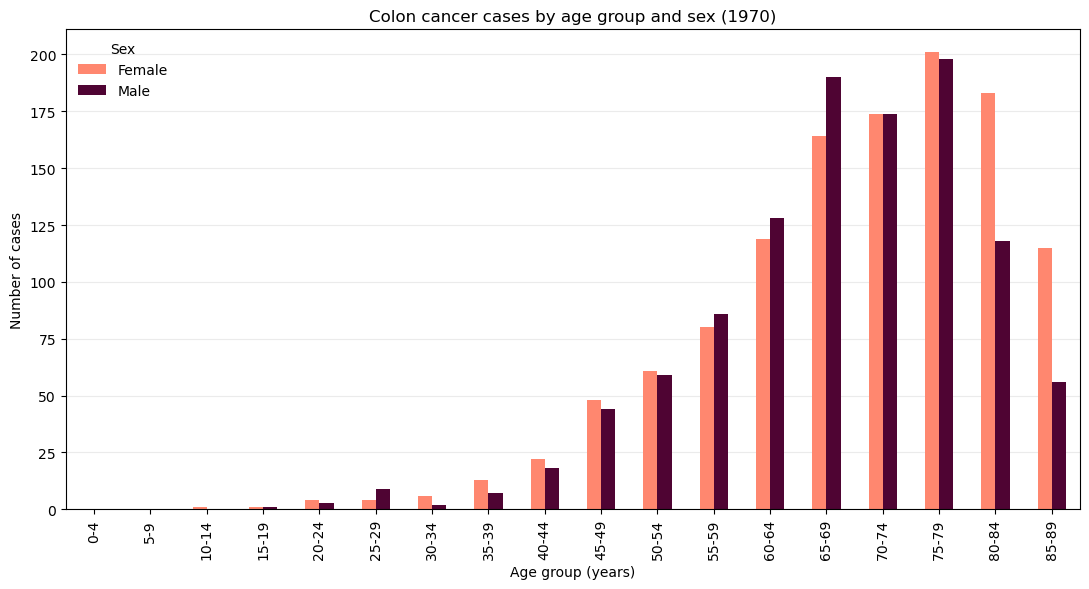

In [24]:
# create a graph of the number of cases by age group and sex for 1970
year_to_plot = cases["year"].min()
age_order = sorted(cases["agegroup"].unique(), key=lambda age: int(age.split("-")[0]))
case_counts = (
    cases.loc[cases["year"].eq(year_to_plot)]
    .pivot(index="agegroup", columns="sex", values="n")
    .reindex(age_order)
)

ax = case_counts.plot(
    kind="bar",
    figsize=(11, 6),
    color=[colors[sex] for sex in case_counts.columns],
)
ax.set_title(f"Colon cancer cases by age group and sex ({year_to_plot})")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Number of cases")
ax.legend(title="Sex", frameon=False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Task 2
Obtain the total number of cases in each calendar year by males and females. Create graphs showing the number of cases over calendar years, separately for males and females. Describe what you can conclude from the graphs.

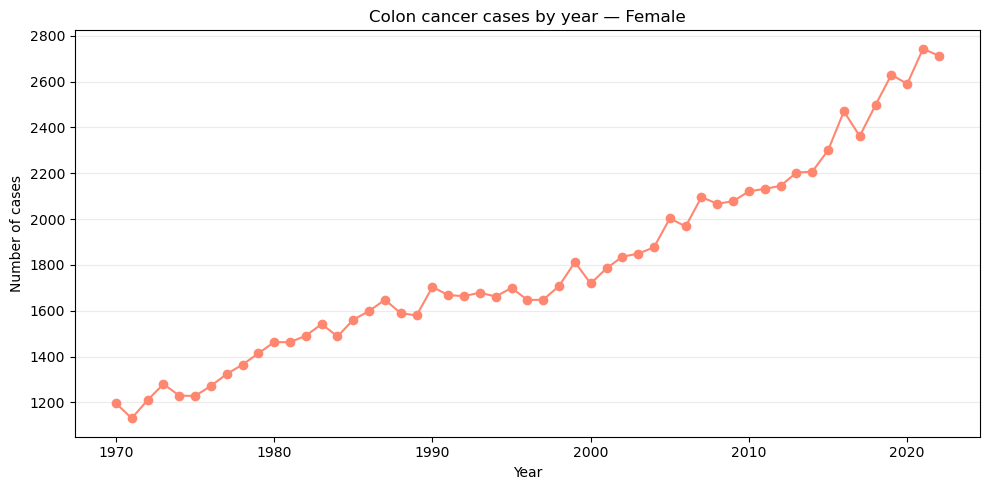

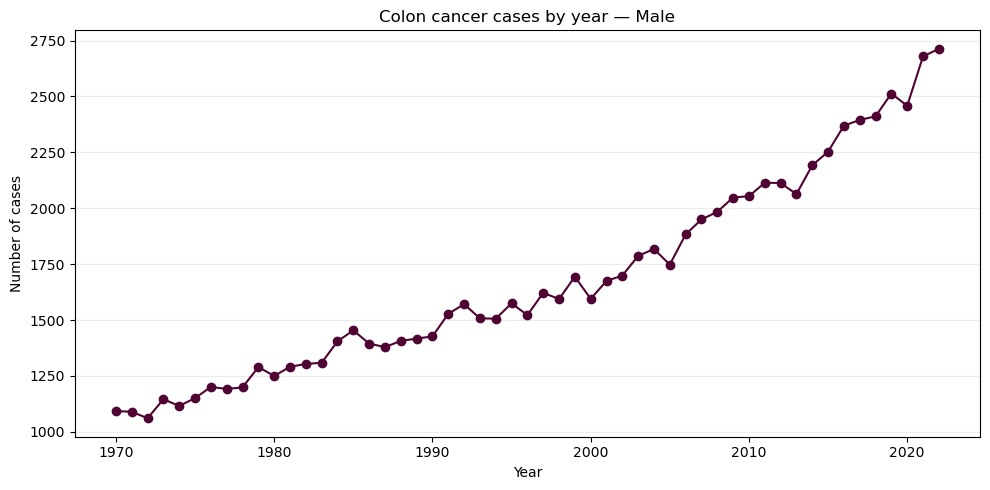

In [26]:
# Total cases per calendar year, shown separately by sex
yearly_cases = cases.groupby(["year", "sex"])["n"].sum().unstack().sort_index()

for sex in yearly_cases.columns:
    ax = yearly_cases[sex].plot(
        figsize=(10, 5),
        marker="o",
        color=colors[sex],
    )
    ax.set_title(f"Colon cancer cases by year — {sex}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Number of cases")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

## Task 3
Read in the file on number of persons at risk (the file population.tsv). Make sure that you understand the variables included. Create graphs that illustrate the population size over age groups and calendar year simultaneously, separately by males and females. Describe what you observe.

In [27]:
population = pd.read_csv("population.tsv", sep="\t")
print(population.head())

  agegroup   sex  year   n_pop
0      0-4  Male  1970  296143
1      5-9  Male  1970  295092
2    10-14  Male  1970  272559
3    15-19  Male  1970  281997
4    20-24  Male  1970  336648


In [28]:
print(population.info())
print(population.describe())

<class 'pandas.DataFrame'>
RangeIndex: 1908 entries, 0 to 1907
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   agegroup  1908 non-null   str  
 1   sex       1908 non-null   str  
 2   year      1908 non-null   int64
 3   n_pop     1908 non-null   int64
dtypes: int64(2), str(2)
memory usage: 59.8 KB
None
              year          n_pop
count  1908.000000    1908.000000
mean   1996.000000  248346.640461
std      15.301069   72703.357589
min    1970.000000   26513.000000
25%    1983.000000  215563.500000
50%    1996.000000  269226.500000
75%    2009.000000  299041.500000
max    2022.000000  400939.000000


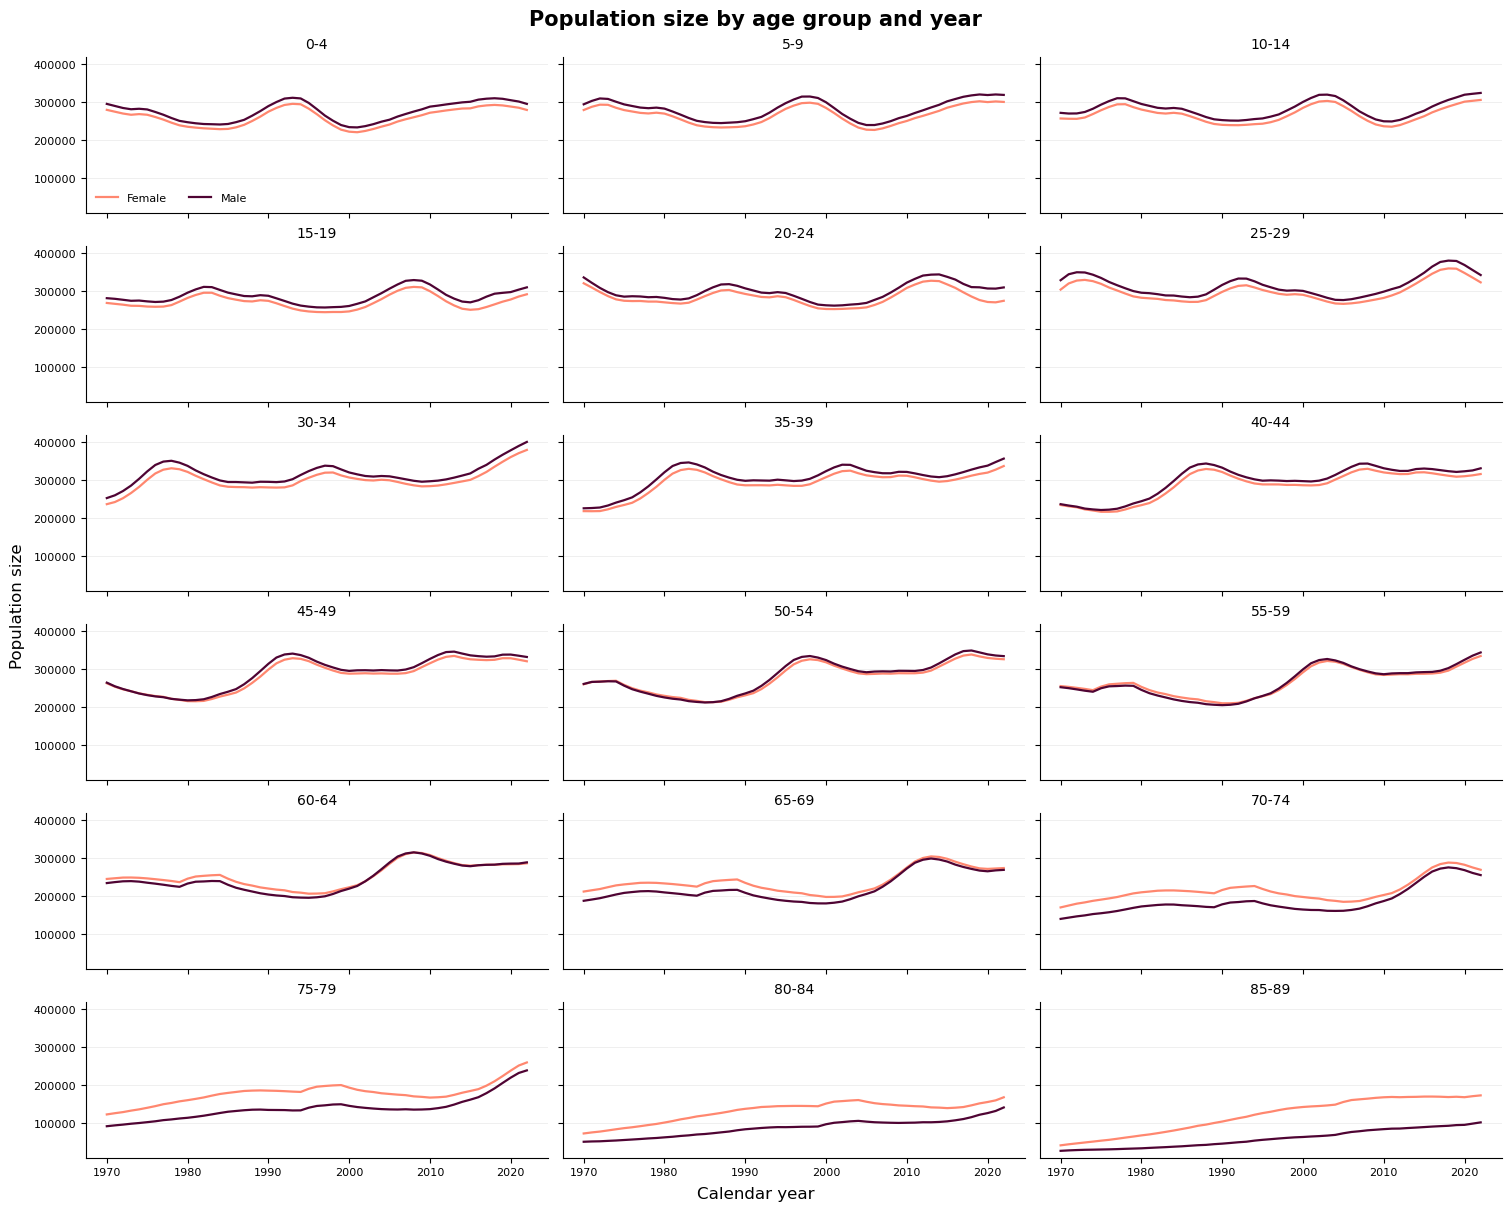

In [36]:
years = sorted(population["year"].unique())
year_ticks = years[::10]
fig, axes = plt.subplots(
    6,
    3,
    figsize=(15, 12),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
legend_handles = []

for index, (ax, agegroup) in enumerate(zip(axes.flat, age_order)):
    for sex in ["Female", "Male"]:
        age_data = population.loc[
            population["sex"].eq(sex) & population["agegroup"].eq(agegroup)
        ].sort_values("year")
        line, = ax.plot(
            age_data["year"],
            age_data["n_pop"],
            color=colors[sex],
            linewidth=1.6,
            label=sex if index == 0 else None,
        )
        if index == 0:
            legend_handles.append(line)

    ax.set_title(agegroup, fontsize=10)
    ax.set_xticks(year_ticks)
    ax.grid(axis="y", alpha=0.2, linewidth=0.7)
    ax.tick_params(axis="both", labelsize=8)
    if index < 15:
        ax.tick_params(axis="x", labelbottom=False)
    if index == 0:
        ax.legend(legend_handles, ["Female", "Male"], loc="lower left", ncol=2, frameon=False, fontsize=8)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

fig.suptitle("Population size by age group and year", fontsize=15, fontweight="bold")
fig.supxlabel("Calendar year")
fig.supylabel("Population size")
plt.show()

## Task 4
Merge the information on number of cases and the number of persons at risk in each year, for each age group and sex. Does the population file include the same age groups and calendar years as the file including the number of cases? Also create a separate data frame with the total number of cases and the total population size in each calendar year by males and females.



In [37]:
# Merge cases with population by age group, sex, and year
case_population = cases.merge(
    population,
    on=["agegroup", "sex", "year"],
    how="outer",
    validate="one_to_one",
    indicator=True,
).sort_values(["year", "sex", "agegroup"]).reset_index(drop=True)

print(case_population.head())
print("\nMerge status:")
print(case_population["_merge"].value_counts())

  agegroup  year     sex  n   n_pop _merge
0      0-4  1970  Female  0  280468   both
1    10-14  1970  Female  1  257746   both
2    15-19  1970  Female  1  269428   both
3    20-24  1970  Female  4  321292   both
4    25-29  1970  Female  4  304581   both

Merge status:
_merge
both          1908
left_only        0
right_only       0
Name: count, dtype: int64


In [38]:
annual_totals = (
    cases.groupby(["year", "sex"], as_index=False)["n"]
    .sum()
    .merge(
        population.groupby(["year", "sex"], as_index=False)["n_pop"].sum(),
        on=["year", "sex"],
        how="outer",
        validate="one_to_one",
    )
    .rename(columns={"n": "total_cases", "n_pop": "total_population"})
    .sort_values(["year", "sex"])
    .reset_index(drop=True)
)

print(annual_totals.head())

   year     sex  total_cases  total_population
0  1970  Female         1196           4045318
1  1970    Male         1093           4035911
2  1971  Female         1131           4066592
3  1971    Male         1090           4048573
4  1972  Female         1210           4077814


In [ ]:
# double check if the age groups and years in the cases and population datasets match (even tho the merge status kinda gives that away)
case_age_groups = set(cases["agegroup"].unique())
population_age_groups = set(population["agegroup"].unique())
case_years = set(cases["year"].unique())
population_years = set(population["year"].unique())

print("Same age groups:", case_age_groups == population_age_groups)
print("Same calendar years:", case_years == population_years)
print("Age groups only in cases:", sorted(case_age_groups - population_age_groups))
print("Age groups only in population:", sorted(population_age_groups - case_age_groups))
print("Years only in cases:", sorted(case_years - population_years))
print("Years only in population:", sorted(population_years - case_years))

Same age groups: True
Same calendar years: True
Age groups only in cases: []
Age groups only in population: []
Years only in cases: []
Years only in population: []


## Task 5
Create a new variable for the incidence rate of colon cancer by dividing the number of cases with the population size. Do this for both the data including all the age groups and the data with the total number of cases per year and sex. Describe shortly what an incidence rate is, and your thoughts on if this is an appropriate way of calculating an incidence rate.

In [ ]:
# Incidence rate for all age groups (plus rate per 100,000 people to make number a bit bigger)
case_population["incidence_rate"] = (
    case_population["n"] / case_population["n_pop"]
)
case_population["incidence_per_100k"] = case_population["incidence_rate"] * 100_000

print(case_population[["agegroup", "year", "sex", "incidence_rate", "incidence_per_100k"]].head())

  agegroup  year     sex  incidence_rate  incidence_per_100k
0      0-4  1970  Female        0.000000            0.000000
1    10-14  1970  Female        0.000004            0.387979
2    15-19  1970  Female        0.000004            0.371157
3    20-24  1970  Female        0.000012            1.244973
4    25-29  1970  Female        0.000013            1.313280


In [ ]:
# Incidence rate for data with total numbers (plus rate per 100,000 people to make number a bit bigger)
annual_totals["incidence_rate"] = (
    annual_totals["total_cases"] / annual_totals["total_population"]
)
annual_totals["incidence_per_100k"] = annual_totals["incidence_rate"] * 100_000

print(annual_totals[["year", "sex", "incidence_rate", "incidence_per_100k"]].head())

   year     sex  incidence_rate  incidence_per_100k
0  1970  Female        0.000296           29.565043
1  1970    Male        0.000271           27.081866
2  1971  Female        0.000278           27.811986
3  1971    Male        0.000269           26.923066
4  1972  Female        0.000297           29.672761
